# 03 – Sensor trust: weather

**Question:** which weather source can we trust for the weather correction in the models?

Three sources:
- **Provider S** and **Provider MB**: hindcast weather models, hourly (wind, waves, currents, sea temperature). Neither is measured on board.
- **Ship's anemometer** (`wind_rel_kn`, `wind_rel_deg`): measured on board every 15 s, but **relative** to the moving ship. It is converted to true wind with the ship's speed and heading before comparing.

Wind and waves are the biggest weather corrections; currents were checked in 02 §6a.

Same rules and steps as the other notebooks (see `README.md`).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, os.path.join("..", "..", "src"))
import trust as T

WX = ["s_wind_e", "s_wind_n", "mb_wind_kn", "mb_wind_deg", "s_hs", "mb_hs", "mb_swell", "s_tp", "s_wave_deg", "s_sst",
      "s_cur_e", "s_cur_n", "mb_cur_e", "mb_cur_n"]
w = T.load_wide(WX + ["wind_rel_kn", "wind_rel_deg", "sog_kn", "heading_deg", "me_rpm", "shaft_rpm"], name="weather")
mode = T.operating_mode(w)
F = T.Findings("03_weather")

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 200, "display.max_columns", 30)

def month_axis(ax):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

# hourly table: provider values sit on the hour; the anemometer and ship speed are averaged over the hour
hourly = w[WX].resample("1h").first()
hourly["s_wind_kn"] = np.hypot(hourly.s_wind_e, hourly.s_wind_n) * T.KN
print(f"{hourly[WX].notna().any(axis=1).sum():,} hours with provider data")

9,307 hours with provider data


## 1. Missing data and placeholders

Provider S has a known placeholder row (DQ-06: 6.0 °C, current −0.4/−0.4, Tp 1.1 s, Hs 0.01 m, wave angle 10°). Provider MB currents are exactly 0 in about 20 % of hours (raw inventory), which is suspicious for a real current.

In [2]:
ph = (hourly.s_sst.round(1) == 6.0) & (hourly.s_cur_e.round(2) == -0.4) & (hourly.s_cur_n.round(2) == -0.4)
mb0 = (hourly.mb_cur_e == 0) & (hourly.mb_cur_n == 0)
ship_mode = mode.resample("1h").agg(lambda x: x.value_counts().idxmax() if len(x) else "unknown")
tab = pd.DataFrame({
    "hours with S": hourly.s_hs.notna().groupby(hourly.index.to_period("M")).sum(),
    "hours with MB": hourly.mb_hs.notna().groupby(hourly.index.to_period("M")).sum(),
    "S placeholder rows": ph.groupby(hourly.index.to_period("M")).sum(),
    "MB currents both exactly 0": mb0.groupby(hourly.index.to_period("M")).sum(),
})
display(tab)
print("S placeholder hours by ship mode:", ship_mode.reindex(hourly.index)[ph].value_counts().to_dict())
print("MB zero-current hours by ship mode:", ship_mode.reindex(hourly.index)[mb0].value_counts().to_dict())
mbz = hourly[mb0]
print(f"MB on zero-current hours: wave height {mbz.mb_hs.median():.2f} m (median, other hours {hourly.mb_hs[~mb0].median():.2f} m), "
      f"wind {mbz.mb_wind_kn.median():.1f} kn — the rest of the row looks real")

,hours with S,hours with MB,S placeholder rows,MB currents both exactly 0
time,,,,
2024-01,738,693,130,246
2024-02,696,696,130,157
2024-03,697,695,53,60
2024-04,720,720,7,11
2024-05,721,614,119,15
2024-06,718,718,152,174
2024-07,719,720,187,275
2024-08,744,744,0,21
2024-09,702,702,96,99


S placeholder hours by ship mode: {'port': 852, 'unknown': 197, 'sailing': 115, 'anchor': 48}
MB zero-current hours by ship mode: {'port': 773, 'anchor': 356, 'unknown': 241, 'sailing': 239}
MB on zero-current hours: wave height 0.30 m (median, other hours 1.90 m), wind 6.3 kn — the rest of the row looks real


## 2. Physical range

In [3]:
lim = {"s_wind_kn": (0, 100), "mb_wind_kn": (0, 100), "s_hs": (0, 20), "mb_hs": (0, 20), "mb_swell": (0, 20),
       "s_tp": (1, 25), "s_sst": (-2, 35), "wind_rel_kn": (0, 120)}
src = hourly.join(w[["wind_rel_kn"]].resample("1h").mean())
rows = []
for c, (lo, hi) in lim.items():
    v = src[c].dropna()
    rows.append({"signal": c, "min": v.min(), "median": v.median(), "max": v.max(), "outside": int(((v < lo) | (v > hi)).sum())})
pd.DataFrame(rows).set_index("signal").round(2)

,min,median,max,outside
signal,,,,
s_wind_kn,0.10,12.05,48.72,0
mb_wind_kn,0.27,11.38,43.97,0
s_hs,0.00,0.52,7.62,0
mb_hs,0.00,1.70,9.60,0
mb_swell,0.00,1.30,6.67,0
s_tp,0.71,3.18,11.74,44
s_sst,2.31,21.43,32.22,0
wind_rel_kn,0.61,18.52,70.30,0


## 3. Anemometer → true wind

The anemometer measures the wind the moving ship feels. With relative speed A, relative angle θ (0° = from ahead) and ship speed V over ground:

true wind speed = √((A·cos θ − V)² + (A·sin θ)²)

Only moments sailing with the engine running are used, averaged per hour.

In [4]:
sail = (mode == "sailing") & (w.me_rpm > 50) & (w.sog_kn > 3)
th = np.deg2rad(w.wind_rel_deg)
tw = np.hypot(w.wind_rel_kn * np.cos(th) - w.sog_kn, w.wind_rel_kn * np.sin(th)).where(sail)
hourly["anemo_true_kn"] = tw.resample("1h").mean()
hourly["anemo_n"] = tw.notna().resample("1h").sum()
hourly.loc[hourly.anemo_n < 120, "anemo_true_kn"] = np.nan          # at least half an hour of sailing in the hour
print(f"hours with anemometer true wind while sailing: {hourly.anemo_true_kn.notna().sum():,}")

hours with anemometer true wind while sailing: 5,991


## 4. Cross-checks

Hourly pairs (S placeholder hours removed). Bias = median difference; agreement = correlation and median absolute difference.

,hours,correlation,bias (first − second),median |difference|,first median,second median
pair,,,,,,
wind S vs MB [kn],8093,0.84,0.80,1.83,13.25,12.57
wind: ship vs S [kn],5866,0.75,2.35,3.69,15.67,13.82
wind: ship vs MB [kn],5866,0.85,3.24,3.65,15.67,12.90
wave height S vs MB [m],8093,0.76,-0.92,0.93,0.66,1.80
current east S vs MB [m/s],7443,0.58,0.03,0.12,-0.01,-0.03
current north S vs MB [m/s],7443,0.44,-0.01,0.11,-0.01,-0.01


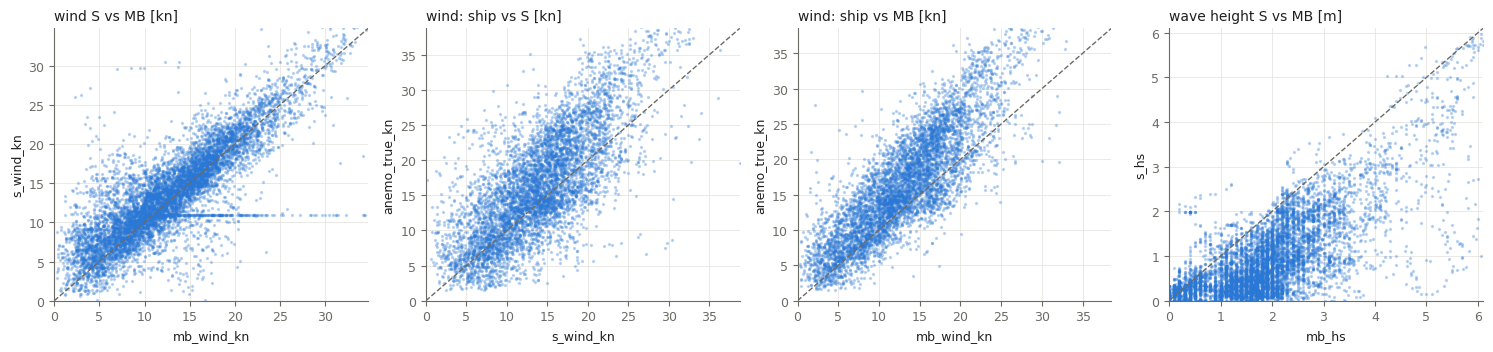

In [5]:
good = ~ph
pairs = [("s_wind_kn", "mb_wind_kn", "wind S vs MB [kn]"),
         ("anemo_true_kn", "s_wind_kn", "wind: ship vs S [kn]"),
         ("anemo_true_kn", "mb_wind_kn", "wind: ship vs MB [kn]"),
         ("s_hs", "mb_hs", "wave height S vs MB [m]"),
         ("s_cur_e", "mb_cur_e", "current east S vs MB [m/s]"),
         ("s_cur_n", "mb_cur_n", "current north S vs MB [m/s]")]
rows = []
for a, b, name in pairs:
    x = hourly.loc[good & ~(mb0 & name.startswith("current")), [a, b]].dropna()
    rows.append({"pair": name, "hours": len(x), "correlation": x.corr().iloc[0, 1], "bias (first − second)": (x[a] - x[b]).median(),
                 "median |difference|": (x[a] - x[b]).abs().median(), "first median": x[a].median(), "second median": x[b].median()})
agree = pd.DataFrame(rows).set_index("pair").round(2)
display(agree)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (a, b, name) in zip(axes, pairs[:4]):
    x = hourly.loc[good, [a, b]].dropna()
    ax.scatter(x[b], x[a], s=2, color=BLUE, alpha=0.25, rasterized=True)
    hi = np.nanpercentile(x.values, 99.5)
    ax.plot([0, hi], [0, hi], color=MUTED, ls="--", lw=1); ax.set_xlim(0, hi); ax.set_ylim(0, hi)
    ax.set_xlabel(b); ax.set_ylabel(a); ax.set_title(name, loc="left", color=INK)
fig.tight_layout(); plt.show()

### 4b. Over time

Daily median of each difference. A step or drift points to a change in one source (e.g. a provider model update or an anemometer problem).

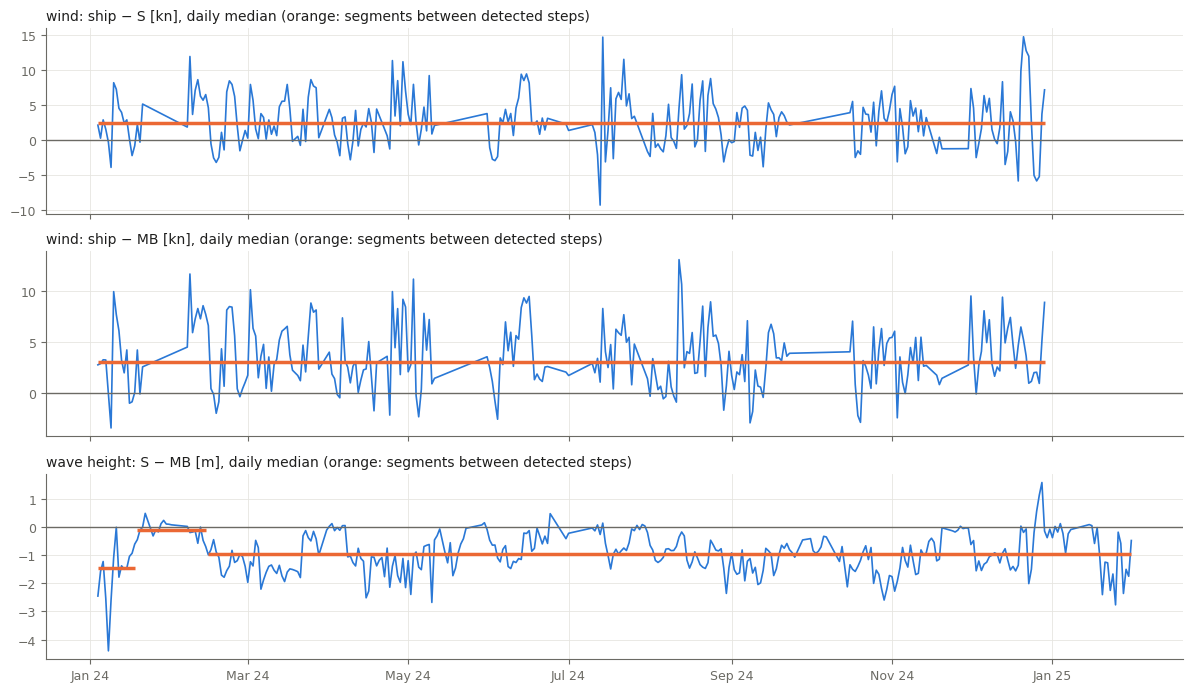

wind: ship − S [kn]


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-12-29,267,2.42,NaN


wind: ship − MB [kn]


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-12-29,267,3.07,NaN


wave height: S − MB [m]


,from,to,days,median,change_vs_previous_%
0,2024-01-04,2024-01-18,15,-1.46,NaN
1,2024-01-19,2024-02-14,20,-0.11,-92.52
2,2024-02-15,2025-01-31,314,-0.95,768.69


In [6]:
diffs = {
    "wind: ship − S [kn]": (hourly.anemo_true_kn - hourly.s_wind_kn).where(good),
    "wind: ship − MB [kn]": (hourly.anemo_true_kn - hourly.mb_wind_kn).where(good),
    "wave height: S − MB [m]": (hourly.s_hs - hourly.mb_hs).where(good),
}
fig, axes = plt.subplots(len(diffs), 1, figsize=(12, 7), sharex=True)
step_tabs = {}
for ax, (name, ser) in zip(axes, diffs.items()):
    d = ser.resample("D").median()
    d = d[ser.resample("D").count() >= 6]
    ax.plot(d.index, d, color=BLUE, lw=1.2); ax.axhline(0, color=MUTED, lw=1)
    st = T.find_steps(d.asfreq("D"))
    step_tabs[name] = st
    for _, s in st.iterrows():
        ax.hlines(s["median"], pd.Timestamp(s["from"]), pd.Timestamp(s["to"]), color=ORANGE, lw=2.5)
    ax.set_title(name + ", daily median (orange: segments between detected steps)", loc="left", color=INK)
month_axis(axes[-1]); fig.tight_layout(); plt.show()
for name, st in step_tabs.items():
    print(name); display(st.round(2))

## 5. Findings

In [7]:
a = agree
sm = ship_mode.reindex(hourly.index)
F.add("`mb_cur_e`, `mb_cur_n`", "all year, mostly in port", "stuck or placeholder value",
      f"Provider MB currents are exactly 0 (east and north together) in {int(mb0.sum()):,} hours, {int(sm[mb0].isin(['port', 'anchor']).sum()):,} of them "
      f"in port or at anchor and {int((sm[mb0] == 'sailing').sum())} while sailing. Provider S writes its placeholder row (DQ-06) mostly in port too "
      f"({int(sm[ph].isin(['port', 'anchor']).sum()):,} of {int(ph.sum()):,} h). Both look like 'no ocean data' near land (grid cell on land)",
      "§1", f"{int(mb0.sum()):,} hours", "Fake zero currents; small at sea", "Set MB currents to NaN when both are exactly 0")
F.add("`wind_rel_kn` vs `s_wind_e/n`, `mb_wind_kn`", "all year", "other",
      f"Wind sources agree reasonably: S vs MB correlation {a.loc['wind S vs MB [kn]', 'correlation']}, ship (anemometer → true wind) vs S "
      f"{a.loc['wind: ship vs S [kn]', 'correlation']}, vs MB {a.loc['wind: ship vs MB [kn]', 'correlation']}. The ship measures "
      f"{a.loc['wind: ship vs S [kn]', 'bias (first − second)']:+.1f} kn vs S and {a.loc['wind: ship vs MB [kn]', 'bias (first − second)']:+.1f} kn vs MB "
      "(median), steady all year (no step): expected, because the anemometer sits high on the mast while providers give wind at 10 m",
      "§3, §4, §4b", f"{int(a.loc['wind: ship vs S [kn]', 'hours']):,} sailing hours", "Choice of source shifts the wind correction",
      "Use the anemometer for wind with a height correction to 10 m (ISO 15016); providers only where it is missing")
F.add("`s_hs`, `mb_hs`", "all year", "other",
      f"Provider S wave height is systematically lower than MB: median {a.loc['wave height S vs MB [m]', 'first median']} vs "
      f"{a.loc['wave height S vs MB [m]', 'second median']} m (correlation {a.loc['wave height S vs MB [m]', 'correlation']}). "
      "MB also gives swell separately, so S may describe wind sea only. No on-board wave measurement to decide",
      "§2, §4", "all hours", "The first-pass prepare_features.py uses S first, which likely underestimates waves",
      "Use MB (total sea) as main source; S as a sensitivity check; report as a limitation")
F.table()

,signal,period,type,what,evidence,affected,impact,options
0,"`mb_cur_e`, `mb_cur_n`","all year, mostly in port",stuck or placeholder value,Provider MB currents are exactly 0 (east and n...,03_weather §1,"1,609 hours",Fake zero currents; small at sea,Set MB currents to NaN when both are exactly 0
1,"`wind_rel_kn` vs `s_wind_e/n`, `mb_wind_kn`",all year,other,Wind sources agree reasonably: S vs MB correla...,"03_weather §3, §4, §4b","5,866 sailing hours",Choice of source shifts the wind correction,Use the anemometer for wind with a height corr...
2,"`s_hs`, `mb_hs`",all year,other,Provider S wave height is systematically lower...,"03_weather §2, §4",all hours,The first-pass prepare_features.py uses S firs...,Use MB (total sea) as main source; S as a sens...


In [8]:
print(F.markdown_rows(first_id=32))

| DQ-32 | `mb_cur_e`, `mb_cur_n` | all year, mostly in port | stuck or placeholder value | Provider MB currents are exactly 0 (east and north together) in 1,609 hours, 1,129 of them in port or at anchor and 239 while sailing. Provider S writes its placeholder row (DQ-06) mostly in port too (900 of 1,212 h). Both look like 'no ocean data' near land (grid cell on land) | 03_weather §1 | 1,609 hours | Fake zero currents; small at sea | Set MB currents to NaN when both are exactly 0 | | open | mp, 28 Oct |
| DQ-33 | `wind_rel_kn` vs `s_wind_e/n`, `mb_wind_kn` | all year | other | Wind sources agree reasonably: S vs MB correlation 0.84, ship (anemometer → true wind) vs S 0.75, vs MB 0.85. The ship measures +2.4 kn vs S and +3.2 kn vs MB (median), steady all year (no step): expected, because the anemometer sits high on the mast while providers give wind at 10 m | 03_weather §3, §4, §4b | 5,866 sailing hours | Choice of source shifts the wind correction | Use the anemometer for wind with a he

## Notes

**Pipeline warning:** the DuckDB database in `src/make_10min.py` (`create_database`) maps signal names by quantity name only, so Provider S and Provider MB wave height and currents get the **same column name** and are **averaged together** in the wide table. Use the Parquet data (`src/load_raw.py`, `src/trust.py`) for weather until that is fixed.

Write your own observations here.